# Indicador TSI provisional
Analiza el indicador normalizado dentro de cada fuente. No es aun el TSI final ni una etiqueta de modelado.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output' / 'indicador_tsi'
tsi = pd.read_csv(RESULTS / 'tsi_provisional_diario.csv') 
method = json.loads((RESULTS / 'metodo.json').read_text(encoding='utf-8'))
print(method)
display(tsi.head())

{'tipo': 'provisional', 'normalizacion': 'min_max_dentro_de_cada_fuente_y_metrica', 'escala': '0_100', 'fuentes_mezcladas': False, 'filas_evaluadas': 41770880, 'limitacion': 'requiere validacion de unidades, sensibilidad a extremos y calibracion local'}


,ciudad,fuente,metrica_principal,fecha,observaciones,tsi_provisional_media,tsi_provisional_minimo,tsi_provisional_maximo,direccion
0,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-06,1,2.691687,2.691687,2.691687,lower_is_better
1,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-07,1,61.116274,61.116274,61.116274,lower_is_better
2,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-11,1,35.697024,35.697024,35.697024,lower_is_better
3,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-12,1,50.927190,50.927190,50.927190,lower_is_better
4,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-13,1,52.911582,52.911582,52.911582,lower_is_better


In [2]:
summary = tsi.groupby('fuente', as_index=False).agg(
    dias=('fecha', 'nunique'),
    media_tsi=('tsi_provisional_media', 'mean'),
    minimo_tsi=('tsi_provisional_minimo', 'min'),
    maximo_tsi=('tsi_provisional_maximo', 'max'),
    observaciones=('observaciones', 'sum'),
)
display(summary.sort_values('media_tsi', ascending=False))

,fuente,dias,media_tsi,minimo_tsi,maximo_tsi,observaciones
1,madrid_traffic_points,31,98.609834,0.000000e+00,100.0,12512133
4,sao_paulo_cet,6094,94.243199,0.000000e+00,100.0,5223411
2,metr_la,119,76.741459,0.000000e+00,100.0,7094304
3,pems_bay,181,73.584399,0.000000e+00,100.0,16937700
0,istanbul_traffic_index,3332,54.157017,4.896922e-11,100.0,3332


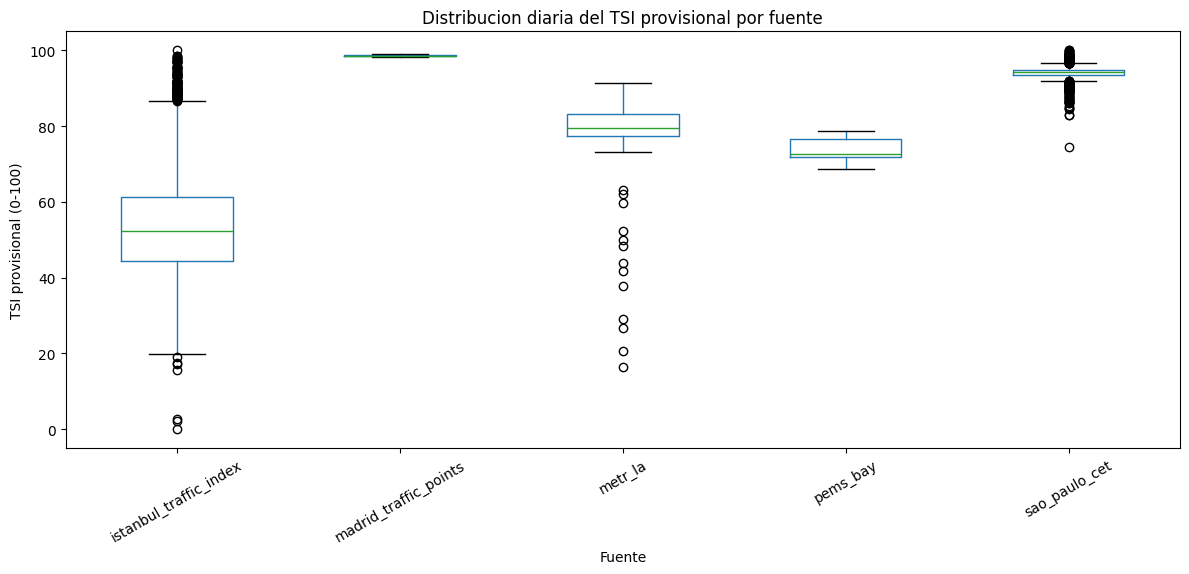

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
tsi.boxplot(column='tsi_provisional_media', by='fuente', ax=ax, grid=False, rot=30)
ax.set_title('Distribucion diaria del TSI provisional por fuente')
ax.set_xlabel('Fuente')
ax.set_ylabel('TSI provisional (0-100)')
plt.suptitle('')
plt.tight_layout()
plt.show()

## Limitaciones
La normalizacion es interna a cada fuente y es sensible a extremos. Antes de usar este indicador para modelos se deben validar unidades, estabilidad temporal y una etiqueta operativa independiente.